In [2]:
import sys
!{sys.executable} -m pip install statsmodels pingouin

Defaulting to user installation because normal site-packages is not writeable


In [19]:
#BASIC LIBRARIES
import numpy as np
import pandas as pd

#VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

#DISPLAY SETTINGS
pd.set_option("display.max_columns", 500)
pd.set_option("display.width", 1000)

#STATISTICAL LIBRARIES
import scipy
import scipy.stats as stats
import statsmodels.api as sm
import pingouin as pg

#RANDOM SEED
SEED = 23243
np.random.seed(SEED)

print("All libraries imported successfully ✔")

All libraries imported successfully ✔


In [20]:
import os
for d in ['orig','data','output']:
    os.makedirs(d,exist_ok=True)

All libraries imported successfully!


In [8]:
df_traintest=pd.read_csv("C:/Users/Acer/Desktop/stock dataset/Combined_setN (1).csv")
print(df_traintest.shape)
display(df_traintest)

(88, 14)


,Company,Period,EPS,ROE%,ROA%,GPM%,OCFPS,RG,NM%,DER,PE,PB,PS,Target_Return
0,CARG,2023Q3,4.40,21.82,4.35,10.25,24.48,-,2.00,2.69,14.86,3.08,0.40,0.063516
1,CARG,2023Q4,7.07,19.78,4.64,10.87,17.85,-,3.35,1.68,15.76,2.86,0.42,0.045139
2,CARG,2024Q1,6.05,21.25,4.76,11.72,-1.56,-,2.60,1.89,15.84,3.09,0.43,0.002639
3,CARG,2024Q2,7.82,21.31,4.94,11.33,30.88,-,3.33,1.67,15.00,2.94,0.42,0.130667
4,CARG,2024Q3,6.36,22.76,4.84,11.38,12.42,-,2.65,1.69,15.38,3.22,0.46,0.023474
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,SAMP,2024Q2,6.16,15.15,1.48,13.46,5.25,-,14.34,0.6,3.75,0.54,0.43,0.506369
84,SAMP,2024Q3,8.20,17.1,1.68,12.29,6.9,-,23.61,0.61,4.83,0.78,0.71,0.006160
85,SAMP,2024Q4,7.61,20.51,1.88,11.38,15.99,-,16.38,0.55,4.25,0.83,0.72,0.095238
86,SAMP,2025Q1,5.72,19.04,1.76,10.88,2.32,-,12.49,0.69,4.57,0.83,0.74,0.152778


In [9]:
df_score=pd.read_csv("C:/Users/Acer/Desktop/stock dataset/Combined_setN (1).csv")
print(df_score.shape)
df_score.head(3)

(88, 14)


,Company,Period,EPS,ROE%,ROA%,GPM%,OCFPS,RG,NM%,DER,PE,PB,PS,Target_Return
0,CARG,2023Q3,4.40,21.82,4.35,10.25,24.48,-,2.00,2.69,14.86,3.08,0.40,0.063516
1,CARG,2023Q4,7.07,19.78,4.64,10.87,17.85,-,3.35,1.68,15.76,2.86,0.42,0.045139
2,CARG,2024Q1,6.05,21.25,4.76,11.72,-1.56,-,2.60,1.89,15.84,3.09,0.43,0.002639


In [10]:
df_traintest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Company        88 non-null     object 
 1   Period         88 non-null     object 
 2   EPS            88 non-null     float64
 3   ROE%           88 non-null     object 
 4   ROA%           88 non-null     object 
 5   GPM%           88 non-null     float64
 6   OCFPS          88 non-null     object 
 7   RG             87 non-null     object 
 8   NM%            88 non-null     float64
 9   DER            88 non-null     object 
 10  PE             88 non-null     float64
 11  PB             88 non-null     object 
 12  PS             88 non-null     float64
 13  Target_Return  88 non-null     float64
dtypes: float64(6), object(8)
memory usage: 9.8+ KB


In [11]:
df_traintest = df_traintest.drop(columns=["RG"])

In [12]:
df_traintest.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Company        88 non-null     object 
 1   Period         88 non-null     object 
 2   EPS            88 non-null     float64
 3   ROE%           88 non-null     object 
 4   ROA%           88 non-null     object 
 5   GPM%           88 non-null     float64
 6   OCFPS          88 non-null     object 
 7   NM%            88 non-null     float64
 8   DER            88 non-null     object 
 9   PE             88 non-null     float64
 10  PB             88 non-null     object 
 11  PS             88 non-null     float64
 12  Target_Return  88 non-null     float64
dtypes: float64(6), object(7)
memory usage: 9.1+ KB


In [89]:
#Columns that should be numeric
num_cols = ["ROE%", "ROA%", "OCFPS", "DER", "PB"]

for col in num_cols:
    df_traintest[col] = (
        df_traintest[col]
        .astype(str)
        .str.replace("%", "", regex=False)
        .str.replace(",", "", regex=False)
        .replace("-", np.nan)
        .astype(float)
    )

In [90]:
df_traintest.dtypes

Company           object
Period            object
EPS              float64
ROE%             float64
ROA%             float64
GPM%             float64
OCFPS            float64
NM%              float64
DER              float64
PE               float64
PB               float64
PS               float64
Target_Return    float64
dtype: object

In [91]:
display(df_traintest)

,Company,Period,EPS,ROE%,ROA%,GPM%,OCFPS,NM%,DER,PE,PB,PS,Target_Return
0,CARG,2023Q3,4.40,21.82,4.35,10.25,24.48,2.00,2.69,14.86,3.08,0.40,0.063516
1,CARG,2023Q4,7.07,19.78,4.64,10.87,17.85,3.35,1.68,15.76,2.86,0.42,0.045139
2,CARG,2024Q1,6.05,21.25,4.76,11.72,-1.56,2.60,1.89,15.84,3.09,0.43,0.002639
3,CARG,2024Q2,7.82,21.31,4.94,11.33,30.88,3.33,1.67,15.00,2.94,0.42,0.130667
4,CARG,2024Q3,6.36,22.76,4.84,11.38,12.42,2.65,1.69,15.38,3.22,0.46,0.023474
...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,SAMP,2024Q2,6.16,15.15,1.48,13.46,5.25,14.34,0.60,3.75,0.54,0.43,0.506369
84,SAMP,2024Q3,8.20,17.10,1.68,12.29,6.90,23.61,0.61,4.83,0.78,0.71,0.006160
85,SAMP,2024Q4,7.61,20.51,1.88,11.38,15.99,16.38,0.55,4.25,0.83,0.72,0.095238
86,SAMP,2025Q1,5.72,19.04,1.76,10.88,2.32,12.49,0.69,4.57,0.83,0.74,0.152778


In [92]:
df_traintest.isna().sum()

Company          0
Period           0
EPS              0
ROE%             0
ROA%             0
GPM%             0
OCFPS            0
NM%              0
DER              0
PE               0
PB               0
PS               0
Target_Return    0
dtype: int64

In [93]:
numeric_cols = df_traintest.select_dtypes(include="float64").columns.tolist()
print("Numeric columns:", numeric_cols)

Numeric columns: ['EPS', 'ROE%', 'ROA%', 'GPM%', 'OCFPS', 'NM%', 'DER', 'PE', 'PB', 'PS', 'Target_Return']


In [94]:
#Fill missing values
# Step 1: Company-wise median
df_traintest[numeric_cols] = df_traintest.groupby("Company")[numeric_cols].transform(
    lambda x: x.fillna(x.median())
)

# Step 2: Global median fallback
df_traintest[numeric_cols] = df_traintest[numeric_cols].fillna(df_traintest[numeric_cols].median())

#Verify
print("\nMissing values after imputation:")
print(df_traintest.isna().sum())

print("\nCleaned DataFrame shape:", df_traintest.shape)
display(df_traintest)


Missing values after imputation:
Company          0
Period           0
EPS              0
ROE%             0
ROA%             0
GPM%             0
OCFPS            0
NM%              0
DER              0
PE               0
PB               0
PS               0
Target_Return    0
dtype: int64

Cleaned DataFrame shape: (88, 13)


,Company,Period,EPS,ROE%,ROA%,GPM%,OCFPS,NM%,DER,PE,PB,PS,Target_Return
0,CARG,2023Q3,4.40,21.82,4.35,10.25,24.48,2.00,2.69,14.86,3.08,0.40,0.063516
1,CARG,2023Q4,7.07,19.78,4.64,10.87,17.85,3.35,1.68,15.76,2.86,0.42,0.045139
2,CARG,2024Q1,6.05,21.25,4.76,11.72,-1.56,2.60,1.89,15.84,3.09,0.43,0.002639
3,CARG,2024Q2,7.82,21.31,4.94,11.33,30.88,3.33,1.67,15.00,2.94,0.42,0.130667
4,CARG,2024Q3,6.36,22.76,4.84,11.38,12.42,2.65,1.69,15.38,3.22,0.46,0.023474
...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,SAMP,2024Q2,6.16,15.15,1.48,13.46,5.25,14.34,0.60,3.75,0.54,0.43,0.506369
84,SAMP,2024Q3,8.20,17.10,1.68,12.29,6.90,23.61,0.61,4.83,0.78,0.71,0.006160
85,SAMP,2024Q4,7.61,20.51,1.88,11.38,15.99,16.38,0.55,4.25,0.83,0.72,0.095238
86,SAMP,2025Q1,5.72,19.04,1.76,10.88,2.32,12.49,0.69,4.57,0.83,0.74,0.152778


In [95]:
df_traintest.isna().sum(axis=0).value_counts()

0    13
Name: count, dtype: int64

In [96]:
df_traintest.isna().sum().sum()

np.int64(0)

In [97]:
numeric_cols = df_traintest.select_dtypes(include="float64").columns
corr = df_traintest[numeric_cols].corr()
print(corr)

                    EPS      ROE%      ROA%      GPM%     OCFPS       NM%       DER        PE        PB        PS  Target_Return
EPS            1.000000  0.520523  0.437070  0.275061  0.405103  0.474386 -0.078029 -0.237338  0.483745  0.284831       0.105518
ROE%           0.520523  1.000000  0.977104  0.706735  0.258352  0.411778 -0.494949 -0.127344  0.979495  0.838688      -0.024028
ROA%           0.437070  0.977104  1.000000  0.742538  0.201972  0.402675 -0.525951 -0.096208  0.958398  0.875352      -0.018000
GPM%           0.275061  0.706735  0.742538  1.000000  0.145540  0.320343 -0.376013 -0.153429  0.691323  0.800057      -0.039300
OCFPS          0.405103  0.258352  0.201972  0.145540  1.000000  0.357067  0.058620 -0.132638  0.246119  0.124096      -0.162370
NM%            0.474386  0.411778  0.402675  0.320343  0.357067  1.000000 -0.442540 -0.269465  0.366997  0.454232      -0.068201
DER           -0.078029 -0.494949 -0.525951 -0.376013  0.058620 -0.442540  1.000000 -0.021617 -0.

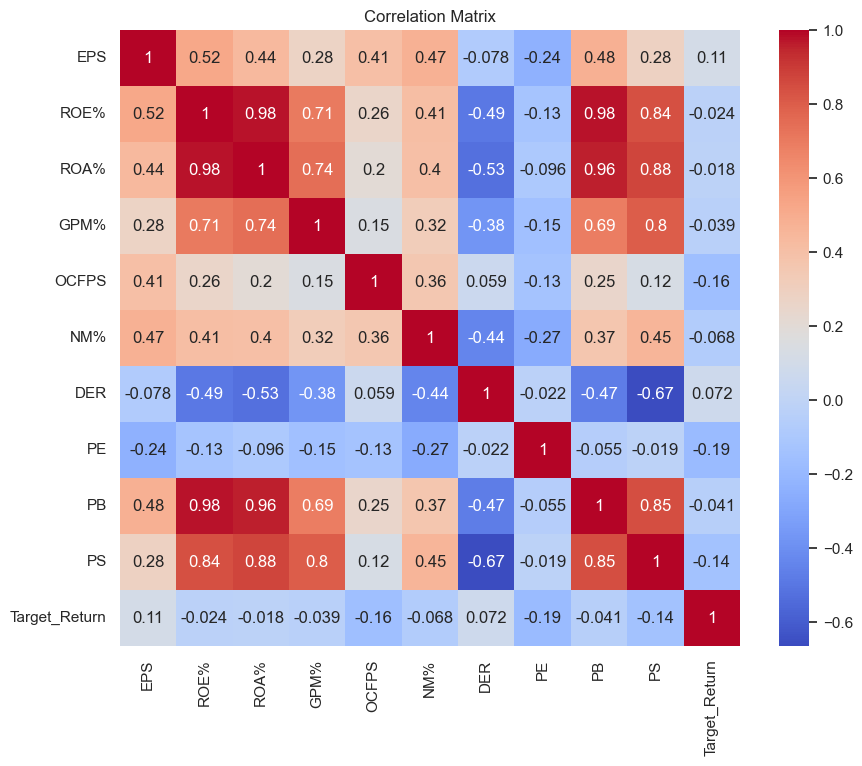

In [98]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10,8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [99]:
#Correlation matrix
numeric_cols = df_traintest.select_dtypes(include="float64").columns
corr_matrix = df_traintest[numeric_cols].corr().abs()

#Upper triangle
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

#Instead of automatic threshold, manually specify PE
to_drop = ['PE', 'OCFPS', 'NM%', 'EPS']  # only drop PE

print("Columns to drop:", to_drop)

#Drop them
df_reduced = df_traintest.drop(columns=to_drop)
print("Shape after dropping PE column:", df_reduced.shape)

Columns to drop: ['PE', 'OCFPS', 'NM%', 'EPS']
Shape after dropping PE column: (88, 9)


Correlation matrix after dropping highly correlated features:
                   ROE%      ROA%      GPM%       DER        PB        PS  Target_Return
ROE%           1.000000  0.977104  0.706735 -0.494949  0.979495  0.838688      -0.024028
ROA%           0.977104  1.000000  0.742538 -0.525951  0.958398  0.875352      -0.018000
GPM%           0.706735  0.742538  1.000000 -0.376013  0.691323  0.800057      -0.039300
DER           -0.494949 -0.525951 -0.376013  1.000000 -0.471081 -0.665199       0.071646
PB             0.979495  0.958398  0.691323 -0.471081  1.000000  0.847200      -0.041395
PS             0.838688  0.875352  0.800057 -0.665199  0.847200  1.000000      -0.141498
Target_Return -0.024028 -0.018000 -0.039300  0.071646 -0.041395 -0.141498       1.000000


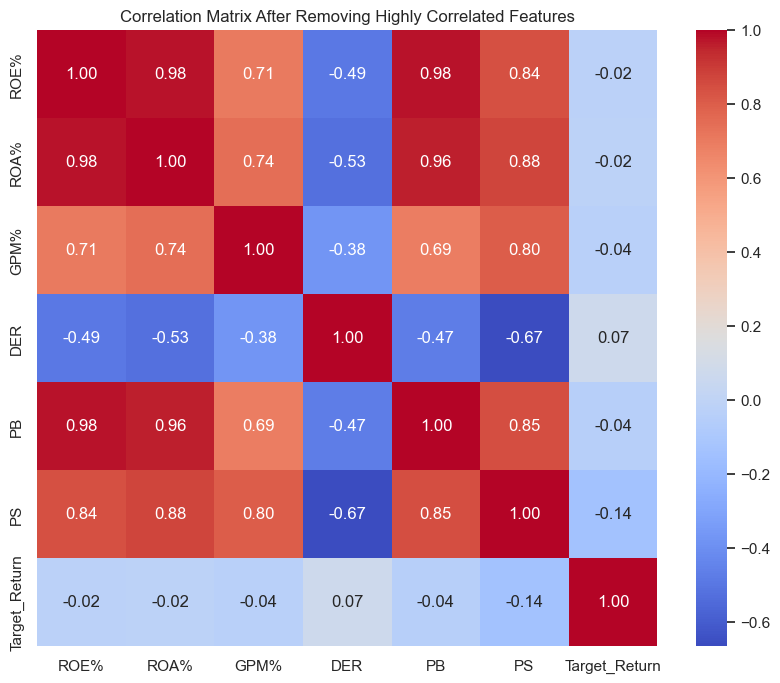

In [100]:
import seaborn as sns
import matplotlib.pyplot as plt

#New numeric columns after dropping
numeric_cols_reduced = df_reduced.select_dtypes(include="float64").columns

#New correlation matrix
corr_matrix_reduced = df_reduced[numeric_cols_reduced].corr()

print("Correlation matrix after dropping highly correlated features:")
print(corr_matrix_reduced)

#Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(corr_matrix_reduced, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix After Removing Highly Correlated Features")
plt.show()

In [101]:
display(df_reduced)

,Company,Period,ROE%,ROA%,GPM%,DER,PB,PS,Target_Return
0,CARG,2023Q3,21.82,4.35,10.25,2.69,3.08,0.40,0.063516
1,CARG,2023Q4,19.78,4.64,10.87,1.68,2.86,0.42,0.045139
2,CARG,2024Q1,21.25,4.76,11.72,1.89,3.09,0.43,0.002639
3,CARG,2024Q2,21.31,4.94,11.33,1.67,2.94,0.42,0.130667
4,CARG,2024Q3,22.76,4.84,11.38,1.69,3.22,0.46,0.023474
...,...,...,...,...,...,...,...,...,...
83,SAMP,2024Q2,15.15,1.48,13.46,0.60,0.54,0.43,0.506369
84,SAMP,2024Q3,17.10,1.68,12.29,0.61,0.78,0.71,0.006160
85,SAMP,2024Q4,20.51,1.88,11.38,0.55,0.83,0.72,0.095238
86,SAMP,2025Q1,19.04,1.76,10.88,0.69,0.83,0.74,0.152778


In [102]:
df_reduced.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88 entries, 0 to 87
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Company        88 non-null     object 
 1   Period         88 non-null     object 
 2   ROE%           88 non-null     float64
 3   ROA%           88 non-null     float64
 4   GPM%           88 non-null     float64
 5   DER            88 non-null     float64
 6   PB             88 non-null     float64
 7   PS             88 non-null     float64
 8   Target_Return  88 non-null     float64
dtypes: float64(7), object(2)
memory usage: 6.3+ KB


In [103]:
from sklearn.model_selection import train_test_split

#Separate features (X) and target (y)
X = df_reduced.drop(columns=["Target_Return"])  #independent variables
y = df_reduced["Target_Return"]                 #dependent variable

#Split into train and test(30% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=SEED
)

#Check shapes
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

X_train shape: (61, 8)
X_test shape: (27, 8)
y_train shape: (61,)
y_test shape: (27,)


In [104]:
target = "Target_Return"
#All columns except the target
features = df_reduced.columns.tolist()
features.remove(target)
print("Feature columns:", features)

Feature columns: ['Company', 'Period', 'ROE%', 'ROA%', 'GPM%', 'DER', 'PB', 'PS']


In [105]:
import pandas as pd

#Original order
company_order = ['CARG', 'CTC', 'DIAL', 'DIST', 'MELS', 'JKH', 'LOFC', 'LOLC', 'COMB', 'HNB', 'SAMP']
period_order = ['2023Q3', '2023Q4', '2024Q1', '2024Q2', '2024Q3', '2024Q4', '2025Q1', '2025Q2']

#Map Company & Period to numbers
company_mapping = {name: i for i, name in enumerate(company_order)}
period_mapping = {q: i for i, q in enumerate(period_order)}

#Map numbers back (for decoding later)
company_reverse_mapping = {v: k for k, v in company_mapping.items()}
period_reverse_mapping = {v: k for k, v in period_mapping.items()}

In [106]:
df_encoded = df_reduced.copy()

#Convert to string and strip spaces
df_encoded['Company'] = df_encoded['Company'].astype(str).str.strip()
df_encoded['Period'] = df_encoded['Period'].astype(str).str.strip()

#Map using mapping dictionaries
df_encoded['Company'] = df_encoded['Company'].map(company_mapping)
df_encoded['Period'] = df_encoded['Period'].map(period_mapping)

df_encoded

,Company,Period,ROE%,ROA%,GPM%,DER,PB,PS,Target_Return
0,0,0,21.82,4.35,10.25,2.69,3.08,0.40,0.063516
1,0,1,19.78,4.64,10.87,1.68,2.86,0.42,0.045139
2,0,2,21.25,4.76,11.72,1.89,3.09,0.43,0.002639
3,0,3,21.31,4.94,11.33,1.67,2.94,0.42,0.130667
4,0,4,22.76,4.84,11.38,1.69,3.22,0.46,0.023474
...,...,...,...,...,...,...,...,...,...
83,10,3,15.15,1.48,13.46,0.60,0.54,0.43,0.506369
84,10,4,17.10,1.68,12.29,0.61,0.78,0.71,0.006160
85,10,5,20.51,1.88,11.38,0.55,0.83,0.72,0.095238
86,10,6,19.04,1.76,10.88,0.69,0.83,0.74,0.152778


In [107]:
#Reverse the mappings to see which number corresponds to which name
company_reverse_mapping = {v: k for k, v in company_mapping.items()}
period_reverse_mapping = {v: k for k, v in period_mapping.items()}

print("Company mapping (number → name):")
print(company_reverse_mapping)

print("\nPeriod mapping (number → name):")
print(period_reverse_mapping)

Company mapping (number → name):
{0: 'CARG', 1: 'CTC', 2: 'DIAL', 3: 'DIST', 4: 'MELS', 5: 'JKH', 6: 'LOFC', 7: 'LOLC', 8: 'COMB', 9: 'HNB', 10: 'SAMP'}

Period mapping (number → name):
{0: '2023Q3', 1: '2023Q4', 2: '2024Q1', 3: '2024Q2', 4: '2024Q3', 5: '2024Q4', 6: '2025Q1', 7: '2025Q2'}


In [129]:
#Import libraries


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMRanker
from sklearn.metrics import classification_report, confusion_matrix, r2_score

import warnings
warnings.filterwarnings("ignore")

In [130]:
df_train,df_test=train_test_split(df_encoded, test_size=0.40,random_state=SEED)
df_train.shape, df_test.shape

((52, 9), (36, 9))

In [131]:
target = 'Target_Return'
features = df_encoded.columns.tolist()
features.remove(target)
print(features)

['Company', 'Period', 'ROE%', 'ROA%', 'GPM%', 'DER', 'PB', 'PS']


In [132]:
X_train = df_train[features]
X_test = df_test[features]
y_train_cont = df_train[target]
y_test_cont = df_test[target]

In [133]:
#Convert continuous target to 2 classes: gains vs losses
y_train = (y_train_cont > 0).astype(int)  # 1 = gain, 0 = loss
y_test  = (y_test_cont > 0).astype(int)

print("Class distribution in training set:\n", y_train.value_counts())
print("Class distribution in test set:\n", y_test.value_counts())

Class distribution in training set:
 Target_Return
1    40
0    12
Name: count, dtype: int64
Class distribution in test set:
 Target_Return
1    25
0    11
Name: count, dtype: int64


In [113]:
#Scale features

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

In [114]:
model = RandomForestClassifier(random_state=SEED)

scores = cross_val_score(model,X_train,y_train,cv=3,n_jobs=-1)

scores.mean(), scores.std()

print(f"classifier RandomForestClassifier has Average CV score is {scores.mean():.2%} with std of {scores.std():0.4}")

classifier RandomForestClassifier has Average CV score is 82.57% with std of 0.05072


In [115]:
model = SVC(random_state=SEED)

scores = cross_val_score(model,X_train,y_train,cv=3,n_jobs=-1)

scores.mean(), scores.std()

print(f"classifier SVC has Average CV score is {scores.mean():.2%} with std of {scores.std():0.4}")

classifier SVC has Average CV score is 76.91% with std of 0.006162


In [116]:
model = DecisionTreeClassifier(random_state=SEED)

scores = cross_val_score(model,X_train,y_train,cv=3,n_jobs=-1)

scores.mean(), scores.std()

print(f"classifier DecisionTreeClassifier has Average CV score is {scores.mean():.2%} with std of {scores.std():0.4}")

classifier DecisionTreeClassifier has Average CV score is 74.84% with std of 0.07692


In [117]:
model = LogisticRegression(max_iter=5000,random_state=SEED)

scores = cross_val_score(model,X_train,y_train,cv=3,n_jobs=-1)

scores.mean(), scores.std()

print(f"classifier Lreg has Average CV score is {scores.mean():.2%} with std of {scores.std():0.4}")

classifier Lreg has Average CV score is 78.98% with std of 0.06773


In [118]:
model = KNeighborsClassifier()

scores = cross_val_score(model,X_train,y_train,cv=3,n_jobs=-1)

scores.mean(), scores.std()

print(f"classifier KNN has Average CV score is {scores.mean():.2%} with std of {scores.std():0.4}")

classifier KNN has Average CV score is 74.95% with std of 0.07478


In [119]:
X_train = df_train[features]
Y_train = df_train[target]

X_test = df_test[features]
Y_test = df_test[target]

In [120]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from xgboost import XGBRegressor

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import numpy as np

In [121]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [122]:
# Example: convert returns into 2 classes: High (1) / Low (0)
Y_class = (Y_train > Y_train.median()).astype(int)

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_val_score

knn = KNeighborsClassifier()
scores = cross_val_score(knn, X_train, Y_class, cv=3)
print(f"KNN CV Accuracy: {scores.mean():.2%} ± {scores.std():.2%}")

KNN CV Accuracy: 44.23% ± 2.41%


In [123]:
# Median split
Y_class = (Y_train > Y_train.median()).astype(int)

# Check how many in each class
print(Y_class.value_counts())

Target_Return
0    26
1    26
Name: count, dtype: int64


In [124]:
def evaluate_regression(model, X_tr, Y_tr, X_te, Y_te):
    model.fit(X_tr, Y_tr)
    y_pred = model.predict(X_te)
    
    r2 = r2_score(Y_te, y_pred)
    rmse = np.sqrt(mean_squared_error(Y_te, y_pred))
    
    print(f"{model.__class__.__name__} -> R²: {r2:.4f}, RMSE: {rmse:.4f}")

In [125]:
# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
evaluate_regression(rf, X_train, Y_train, X_test, Y_test)

# Linear Regression
lr = LinearRegression()
evaluate_regression(lr, X_train_scaled, Y_train, X_test_scaled, Y_test)

# SVR
svr = SVR()
evaluate_regression(svr, X_train_scaled, Y_train, X_test_scaled, Y_test)

# XGBoost Regressor
xgb = XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
evaluate_regression(xgb, X_train, Y_train, X_test, Y_test)

RandomForestRegressor -> R²: 0.2001, RMSE: 0.1524
LinearRegression -> R²: 0.0322, RMSE: 0.1677
SVR -> R²: -0.0400, RMSE: 0.1738
XGBRegressor -> R²: 0.1471, RMSE: 0.1574


In [126]:
# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
evaluate_regression(rf, X_train, Y_train, X_test, Y_test)

# Linear Regression
lr = LinearRegression()
evaluate_regression(lr, X_train_scaled, Y_train, X_test_scaled, Y_test)

# SVR
svr = SVR()
evaluate_regression(svr, X_train_scaled, Y_train, X_test_scaled, Y_test)

# XGBoost Regressor
xgb = XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
evaluate_regression(xgb, X_train, Y_train, X_test, Y_test)


RandomForestRegressor -> R²: 0.2001, RMSE: 0.1524
LinearRegression -> R²: 0.0322, RMSE: 0.1677
SVR -> R²: -0.0400, RMSE: 0.1738
XGBRegressor -> R²: 0.1471, RMSE: 0.1574


In [127]:
def evaluate_regression(model, X_tr, Y_tr, X_te, Y_te):
    model.fit(X_tr, Y_tr)
    y_pred = model.predict(X_te)
    
    r2 = r2_score(Y_te, y_pred) * 100  # convert to percentage
    rmse = np.sqrt(mean_squared_error(Y_te, y_pred))
    
    print(f"{model.__class__.__name__} -> R²: {r2:.2f}%, RMSE: {rmse:.4f}")

In [128]:
# Random Forest
rf = RandomForestRegressor(n_estimators=100, random_state=42)
evaluate_regression(rf, X_train, Y_train, X_test, Y_test)

# Linear Regression
lr = LinearRegression()
evaluate_regression(lr, X_train_scaled, Y_train, X_test_scaled, Y_test)

# SVR
svr = SVR()
evaluate_regression(svr, X_train_scaled, Y_train, X_test_scaled, Y_test)

# XGBoost Regressor
xgb = XGBRegressor(objective='reg:squarederror', n_estimators=100, random_state=42)
evaluate_regression(xgb, X_train, Y_train, X_test, Y_test)

RandomForestRegressor -> R²: 20.01%, RMSE: 0.1524
LinearRegression -> R²: 3.22%, RMSE: 0.1677
SVR -> R²: -4.00%, RMSE: 0.1738
XGBRegressor -> R²: 14.71%, RMSE: 0.1574
